In [36]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
import numpy as np

data = pd.read_csv("../feature_processing/all_data.csv")
data.head()

,race,season,driver,team,lap_time,sector_1_time,sector_2_time,sector_3_time,tyre_compound,tyre_age,...,throttle_speed_corr,fastest_lap,air_temp_mean,air_temp_max,air_temp_min,track_temp_mean,track_temp_max,track_temp_min,session,top10
0,FORMULA 1 GULF AIR BAHRAIN GRAND PRIX 2022,2022,1,Red Bull Racing,94.742,30.224,40.815,23.703,MEDIUM,4.0,...,0.584329,94.193,19.885366,20.2,19.6,34.746341,37.0,32.0,FP1,0.0
1,FORMULA 1 GULF AIR BAHRAIN GRAND PRIX 2022,2022,3,McLaren,96.402,30.592,41.658,24.152,SOFT,9.0,...,0.591420,94.193,19.885366,20.2,19.6,34.746341,37.0,32.0,FP1,0.0
2,FORMULA 1 GULF AIR BAHRAIN GRAND PRIX 2022,2022,4,McLaren,96.304,30.711,41.365,24.228,SOFT,9.0,...,0.579884,94.193,19.885366,20.2,19.6,34.746341,37.0,32.0,FP1,0.0
3,FORMULA 1 GULF AIR BAHRAIN GRAND PRIX 2022,2022,6,Williams,95.644,30.217,41.716,23.711,SOFT,2.0,...,0.645543,94.193,19.885366,20.2,19.6,34.746341,37.0,32.0,FP1,0.0
4,FORMULA 1 GULF AIR BAHRAIN GRAND PRIX 2022,2022,10,AlphaTauri,94.193,30.076,40.492,23.625,SOFT,2.0,...,0.583042,94.193,19.885366,20.2,19.6,34.746341,37.0,32.0,FP1,0.0


In [37]:
data.describe()

/Users/rafaelbeltranhernandez/Documents/git_projects/f1-points-predictor/.venv/lib/python3.14/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
/Users/rafaelbeltranhernandez/Documents/git_projects/f1-points-predictor/.venv/lib/python3.14/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: overflow encountered in square
  sqr = _ensure_numeric((avg - values) ** 2)


,season,driver,lap_time,sector_1_time,sector_2_time,sector_3_time,tyre_age,mean_speed,max_speed,speed_std,...,rpm_speed_corr,throttle_speed_corr,fastest_lap,air_temp_mean,air_temp_max,air_temp_min,track_temp_mean,track_temp_max,track_temp_min,top10
count,5438.000000,5438.000000,5438.000000,5437.000000,5437.000000,5438.000000,5432.000000,5438.000000,5438.000000,5438.000000,...,5359.000000,5359.000000,5438.000000,5438.000000,5438.000000,5438.000000,5438.000000,5438.000000,5438.000000,5304.000000
mean,2023.884332,28.792571,86.311749,26.860006,32.999221,26.445471,4.241348,211.919099,317.933798,67.365455,...,0.711189,0.596141,84.968603,24.278475,24.950294,23.571019,37.282899,39.862523,33.486686,0.496983
std,1.378134,23.861080,11.279610,5.172427,7.152821,5.805636,2.950790,31.667068,36.715592,11.287317,...,0.123784,0.054044,10.855937,5.388949,5.444424,5.402773,9.542918,9.956649,10.437626,0.500038
min,2022.000000,1.000000,64.324000,16.329000,17.110000,16.162000,1.000000,0.000000,0.000000,0.000000,...,0.021364,0.322517,64.324000,11.146296,11.500000,10.700000,12.870988,13.200000,0.000000,0.000000
25%,2023.000000,11.000000,77.137500,23.755000,28.200000,22.210250,2.000000,200.163063,315.000000,62.398558,...,0.681863,0.559323,76.063500,20.334568,21.300000,19.600000,32.013415,34.100000,28.600000,0.000000
50%,2024.000000,22.000000,85.222000,27.509000,32.034000,25.611000,3.000000,214.396611,323.000000,67.100874,...,0.744863,0.595635,84.321000,24.795062,25.300000,23.900000,38.203659,40.900000,34.900000,0.000000
75%,2025.000000,44.000000,93.376750,30.007000,38.368000,29.962000,5.000000,231.992438,331.000000,72.110409,...,0.789392,0.634934,92.065000,28.780519,29.200000,28.000000,43.893827,46.800000,40.000000,1.000000
max,2026.000000,99.000000,135.163000,44.308000,62.324000,45.836000,29.000000,315.000000,356.000000,103.272340,...,0.904679,0.837592,123.207000,35.156250,35.600000,34.800000,58.498780,62.700000,56.900000,1.000000


In [38]:
# Combine counts and percentages into a single DataFrame
balance_df = pd.DataFrame({
    'Count': data['top10'].value_counts(),
    'Percentage': data['top10'].value_counts(normalize=True) * 100
})

print(balance_df)

       Count  Percentage
top10                   
0.0     2668   50.301659
1.0     2636   49.698341


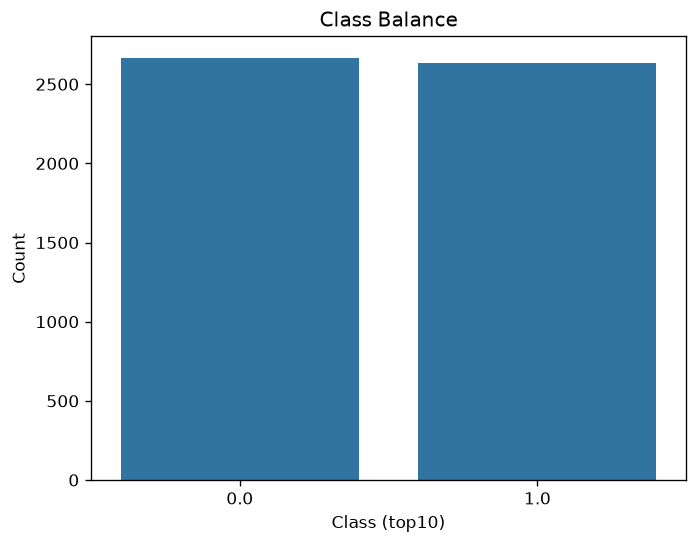

In [39]:
import seaborn as sns

import matplotlib.pyplot as plt

plot_df = balance_df.reset_index()

ax = sns.barplot(data=plot_df, x='top10', y='Count')
ax.set(title='Class Balance', xlabel='Class (top10)', ylabel='Count')

plt.show()

In [40]:
raw_data = data
data.dtypes

race                     object
season                    int64
driver                    int64
team                     object
lap_time                float64
sector_1_time           float64
sector_2_time           float64
sector_3_time           float64
tyre_compound            object
tyre_age                float64
mean_speed              float64
max_speed               float64
speed_std               float64
mean_rpm                float64
max_rpm                 float64
rpm_std                 float64
mean_throttle           float64
mean_gear               float64
speed_curvature_corr    float64
mean_curvature          float64
max_curvature           float64
rpm_speed_corr          float64
throttle_speed_corr     float64
fastest_lap             float64
air_temp_mean           float64
air_temp_max            float64
air_temp_min            float64
track_temp_mean         float64
track_temp_max          float64
track_temp_min          float64
session                  object
top10   

In [41]:
float_columns = data.select_dtypes(include="float").columns.tolist()
float_columns

['lap_time',
 'sector_1_time',
 'sector_2_time',
 'sector_3_time',
 'tyre_age',
 'mean_speed',
 'max_speed',
 'speed_std',
 'mean_rpm',
 'max_rpm',
 'rpm_std',
 'mean_throttle',
 'mean_gear',
 'speed_curvature_corr',
 'mean_curvature',
 'max_curvature',
 'rpm_speed_corr',
 'throttle_speed_corr',
 'fastest_lap',
 'air_temp_mean',
 'air_temp_max',
 'air_temp_min',
 'track_temp_mean',
 'track_temp_max',
 'track_temp_min',
 'top10']

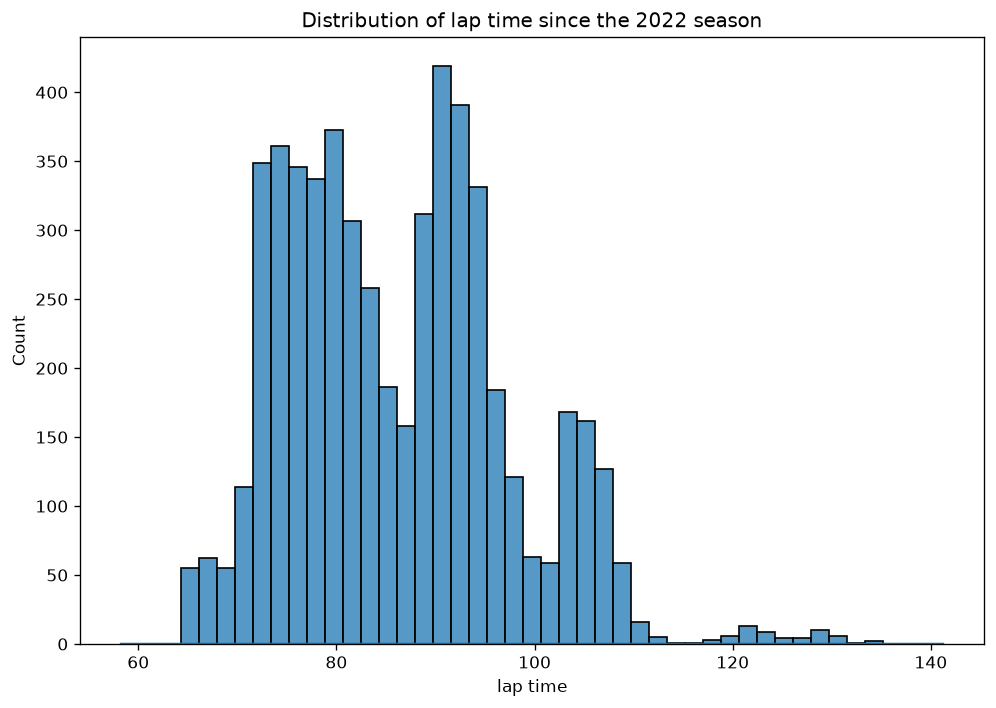

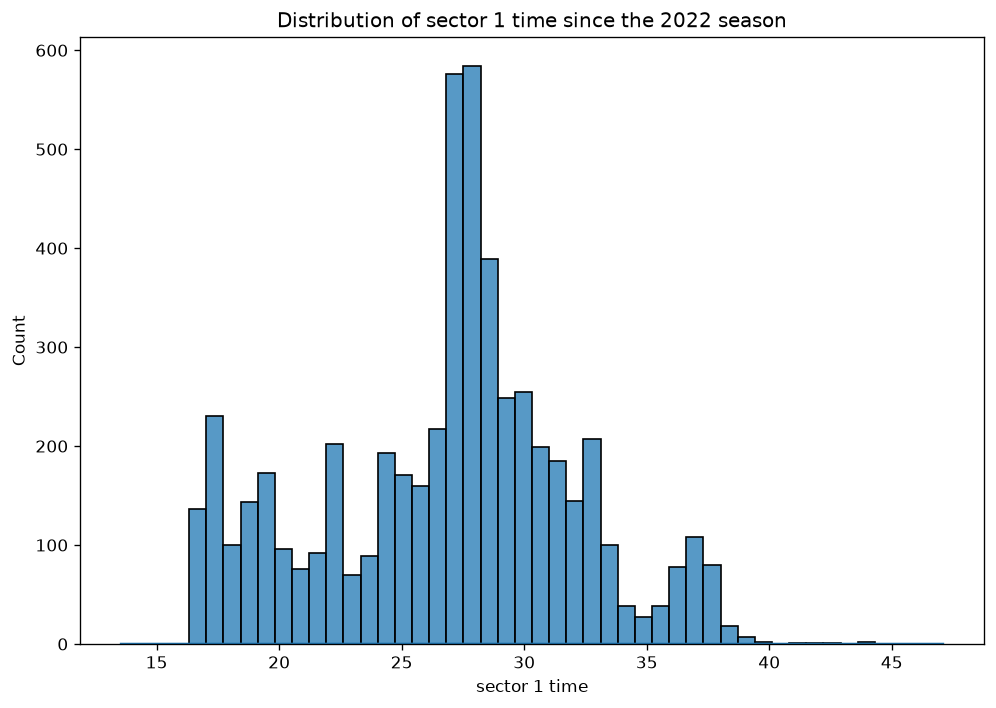

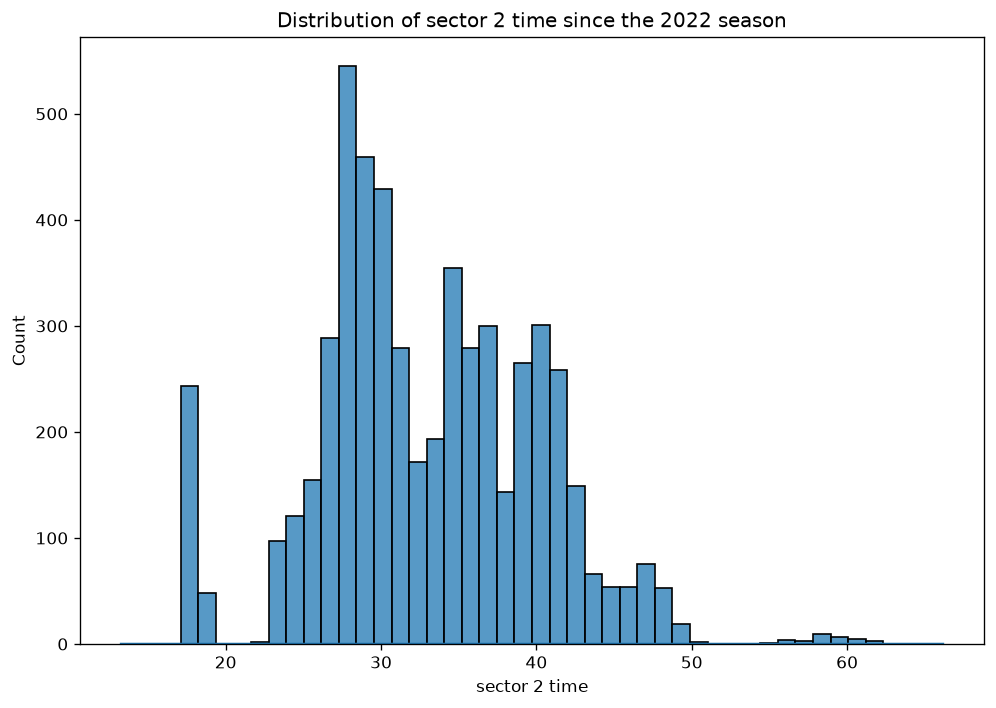

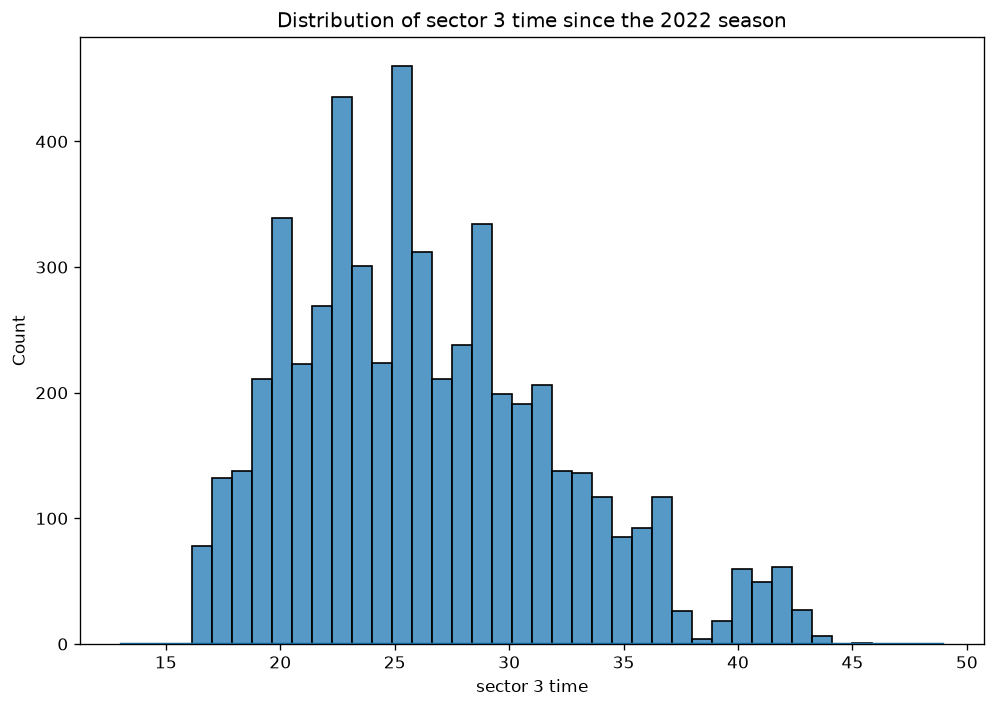

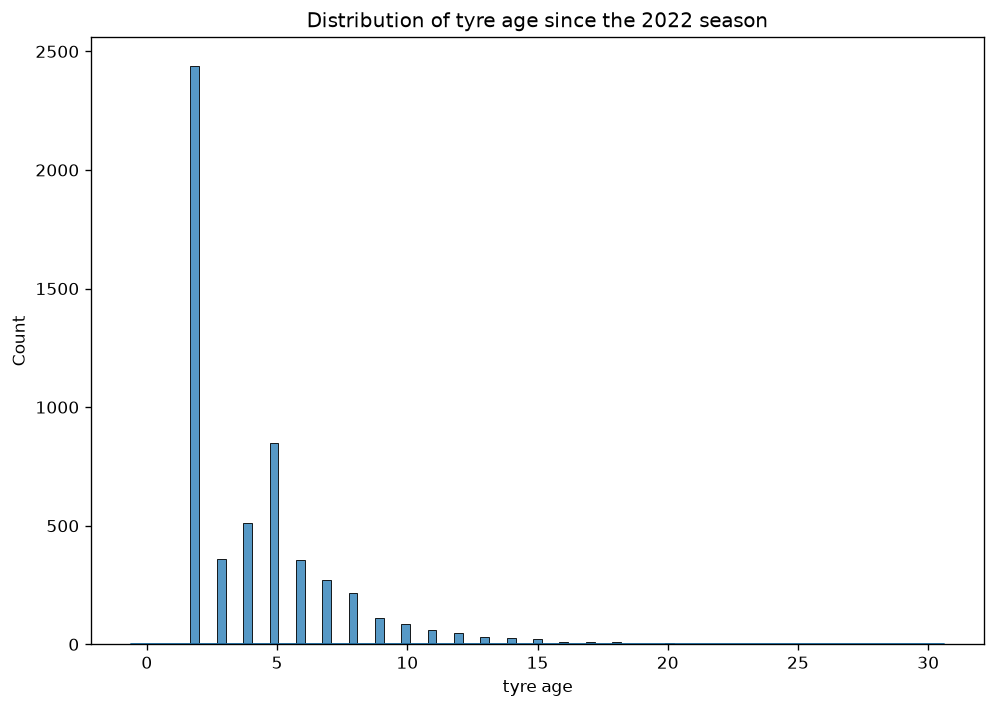

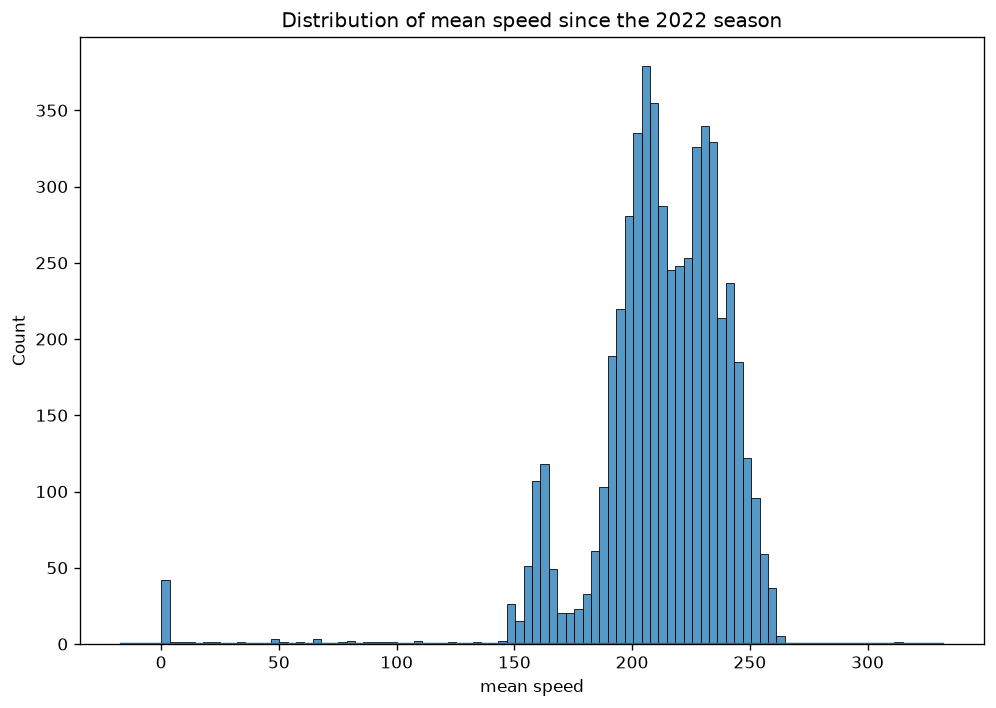

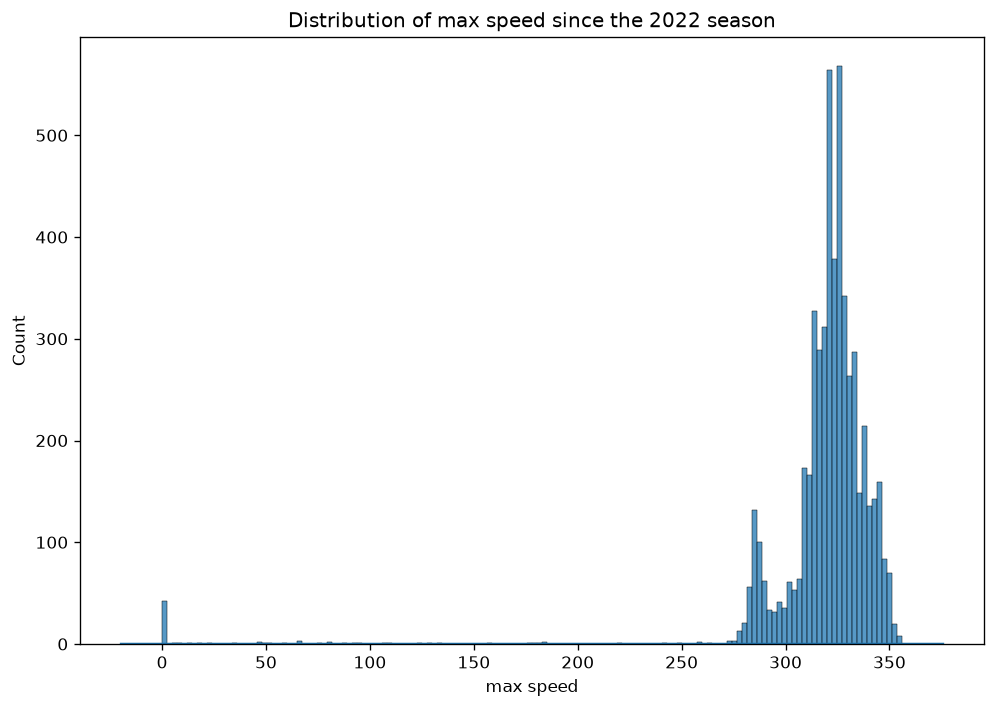

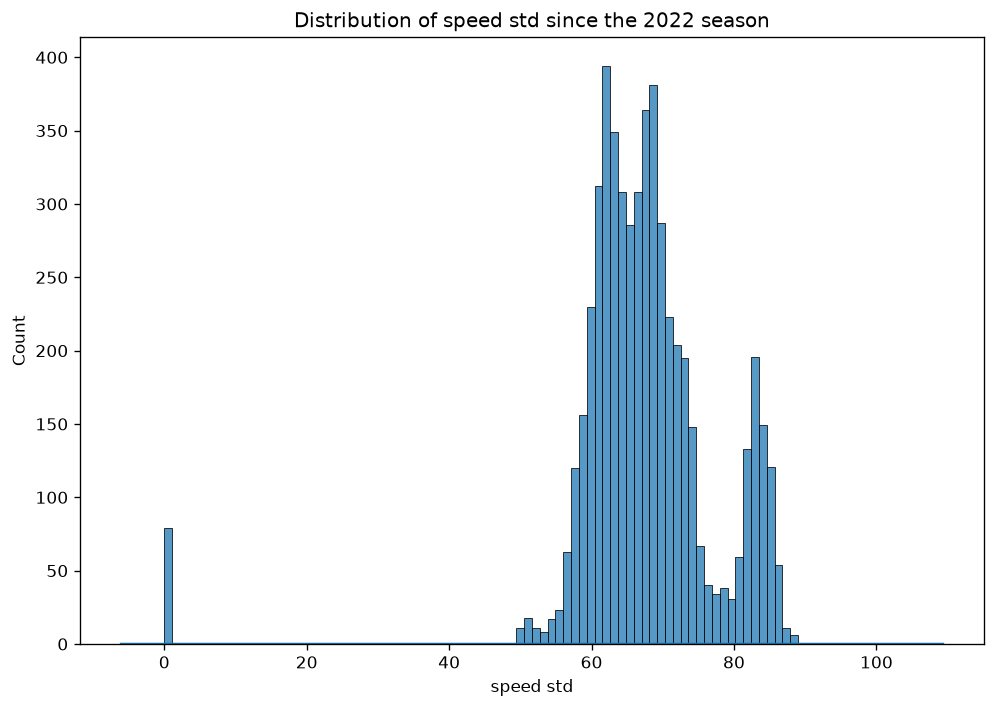

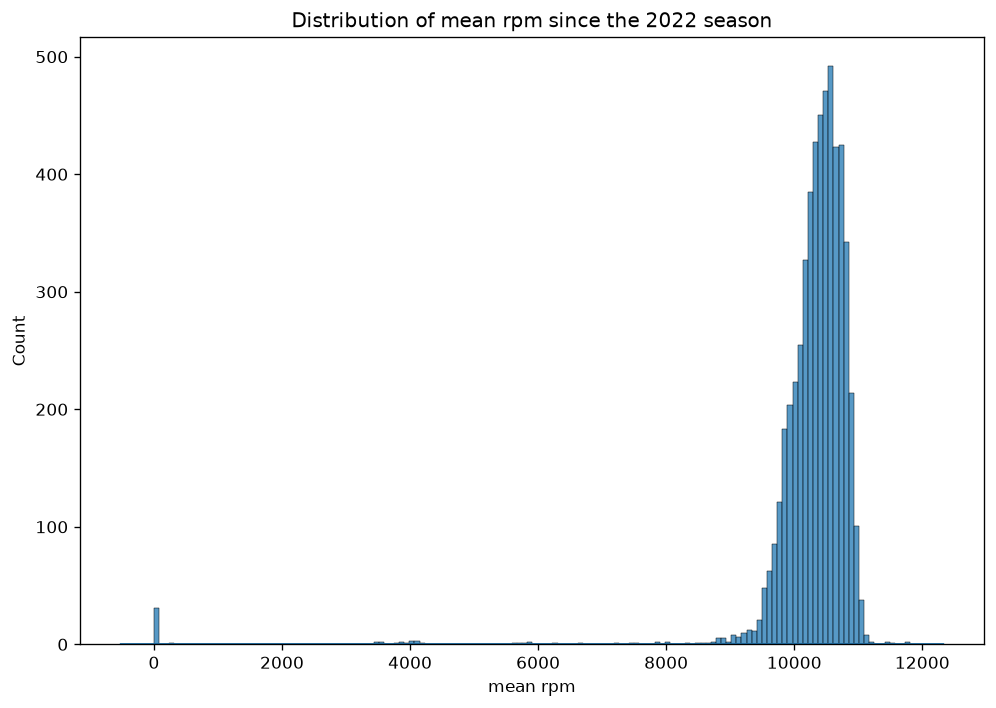

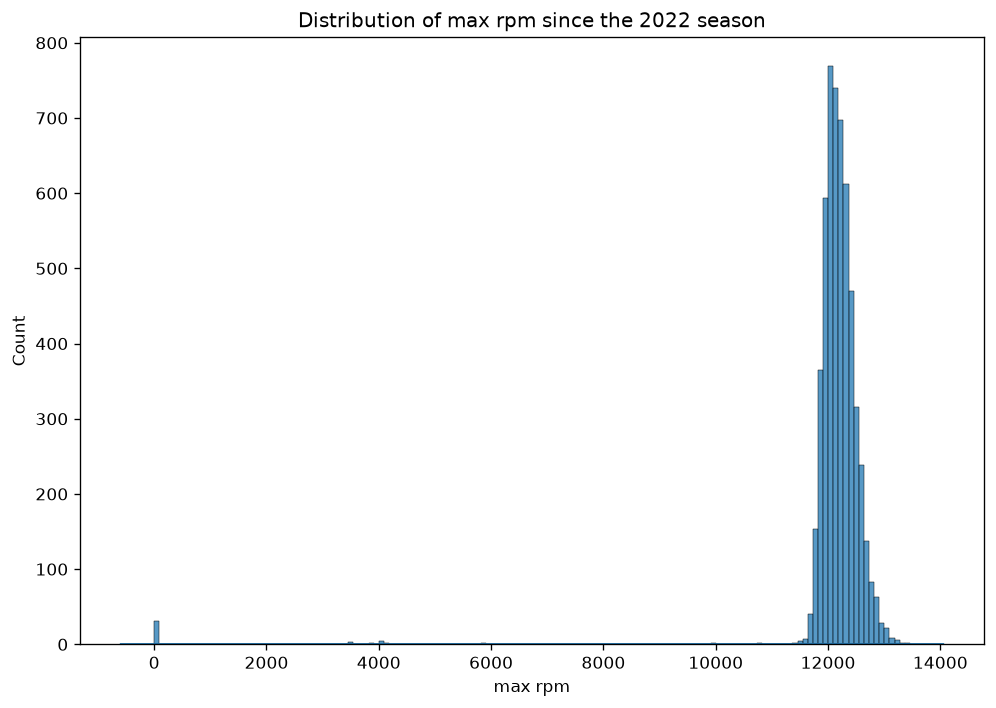

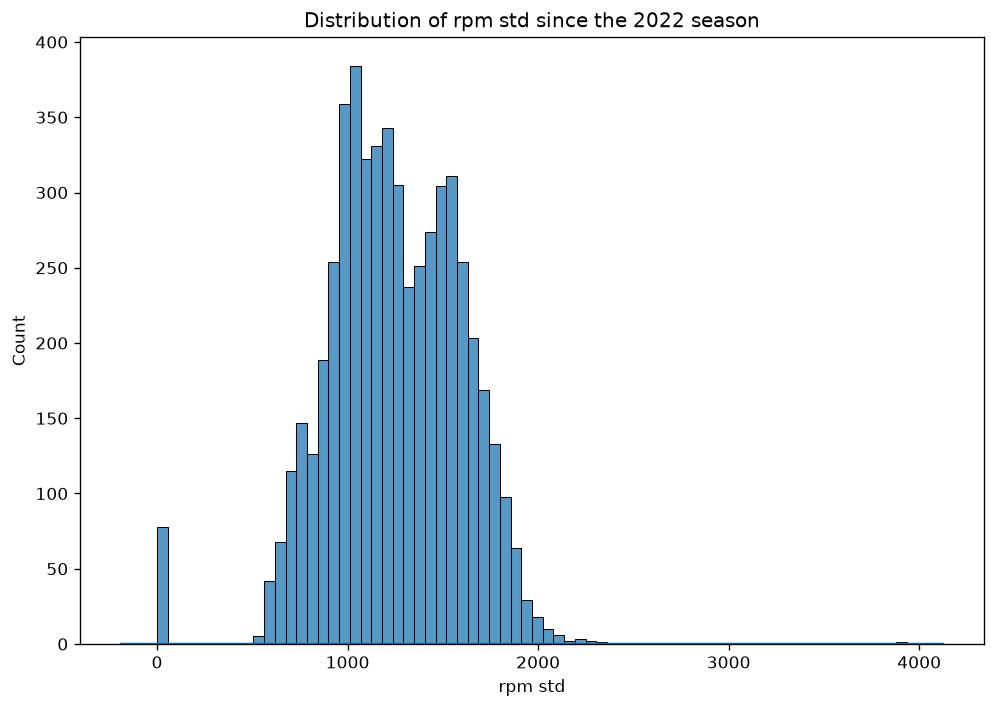

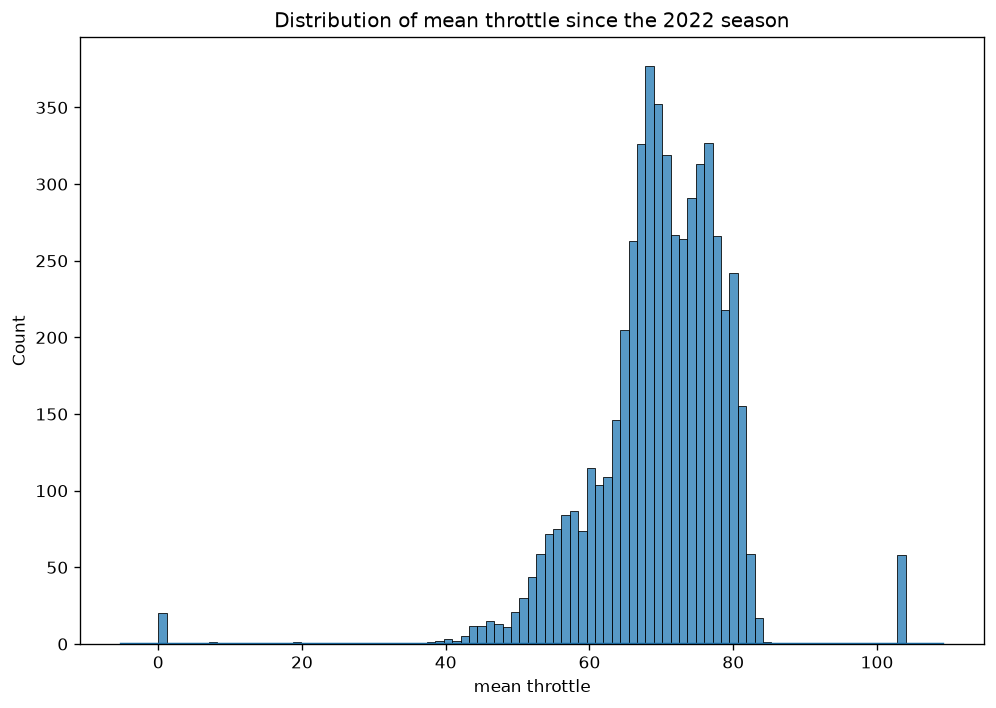

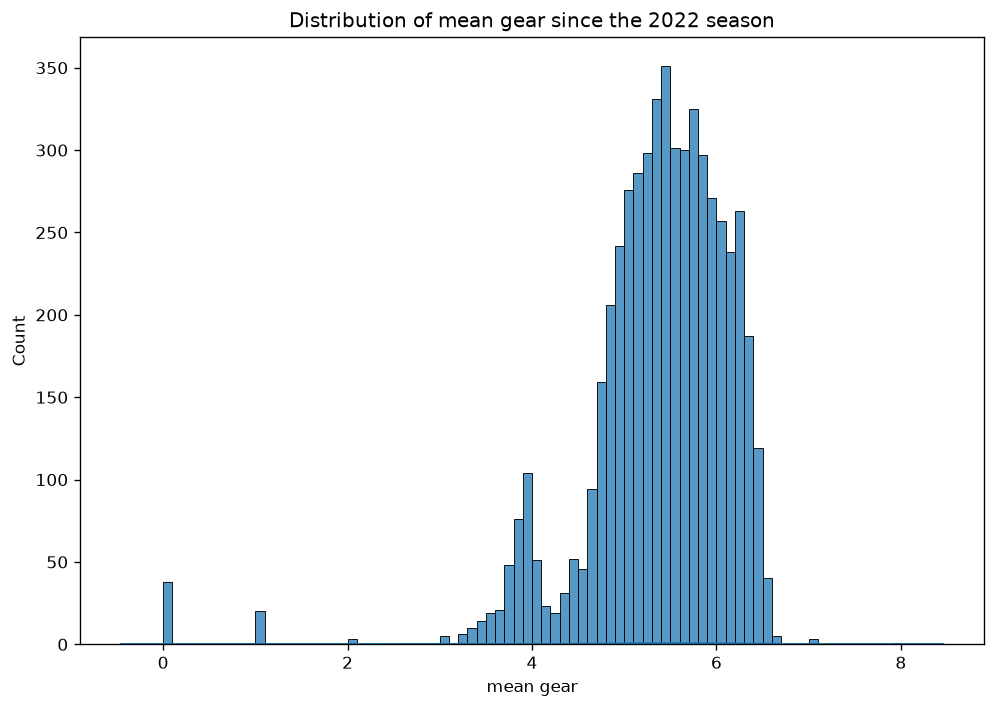

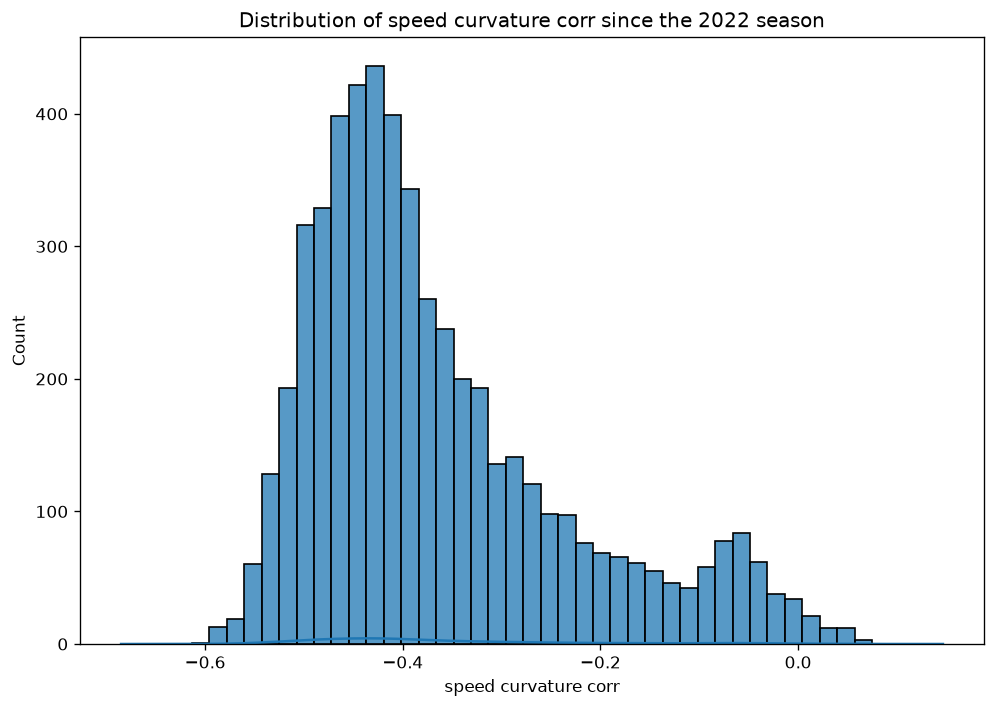

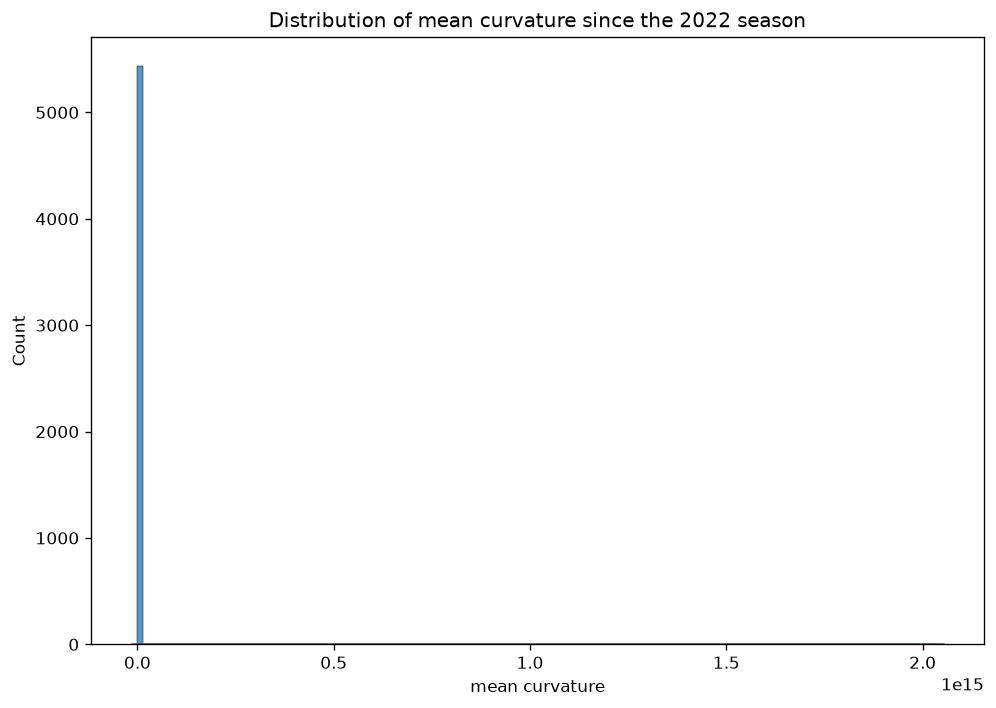

KDE failed for max_curvature: array must not contain infs or NaNs


/Users/rafaelbeltranhernandez/Documents/git_projects/f1-points-predictor/.venv/lib/python3.14/site-packages/matplotlib/axes/_base.py:3211: RuntimeWarning: overflow encountered in scalar add
  x0, x1 = inverse_trans.transform([x0t - delta, x1t + delta])
/Users/rafaelbeltranhernandez/Documents/git_projects/f1-points-predictor/.venv/lib/python3.14/site-packages/seaborn/distributions.py:687: RuntimeWarning: invalid value encountered in subtract
  ax.transData.transform([left_edge + binwidth] * 2)
/Users/rafaelbeltranhernandez/Documents/git_projects/f1-points-predictor/.venv/lib/python3.14/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: overflow encountered in square
  sqr = _ensure_numeric((avg - values) ** 2)


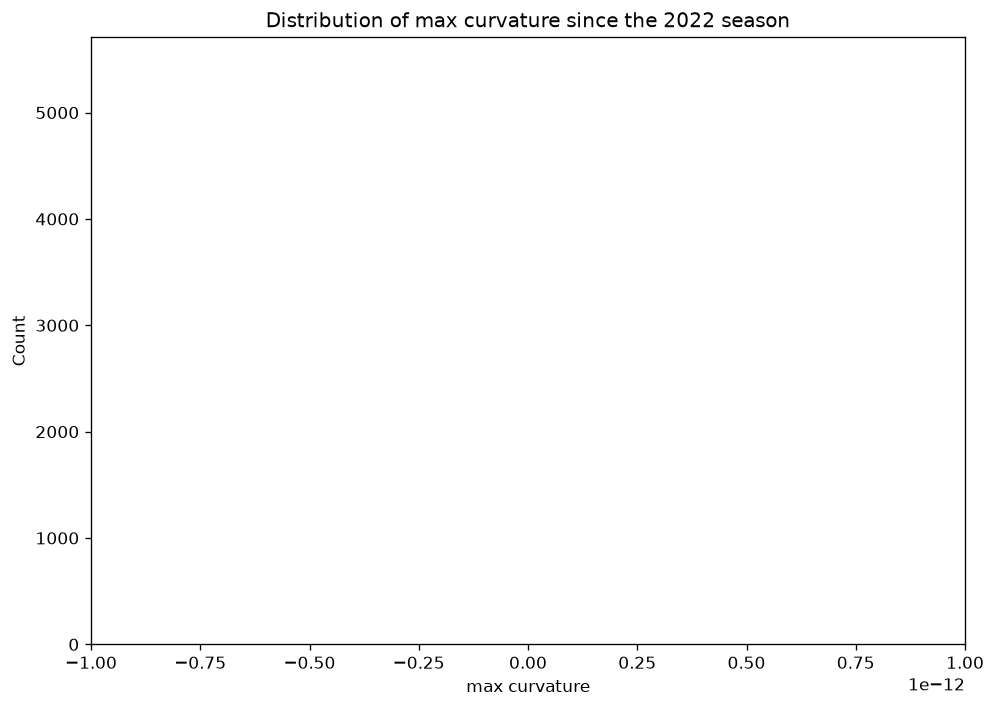

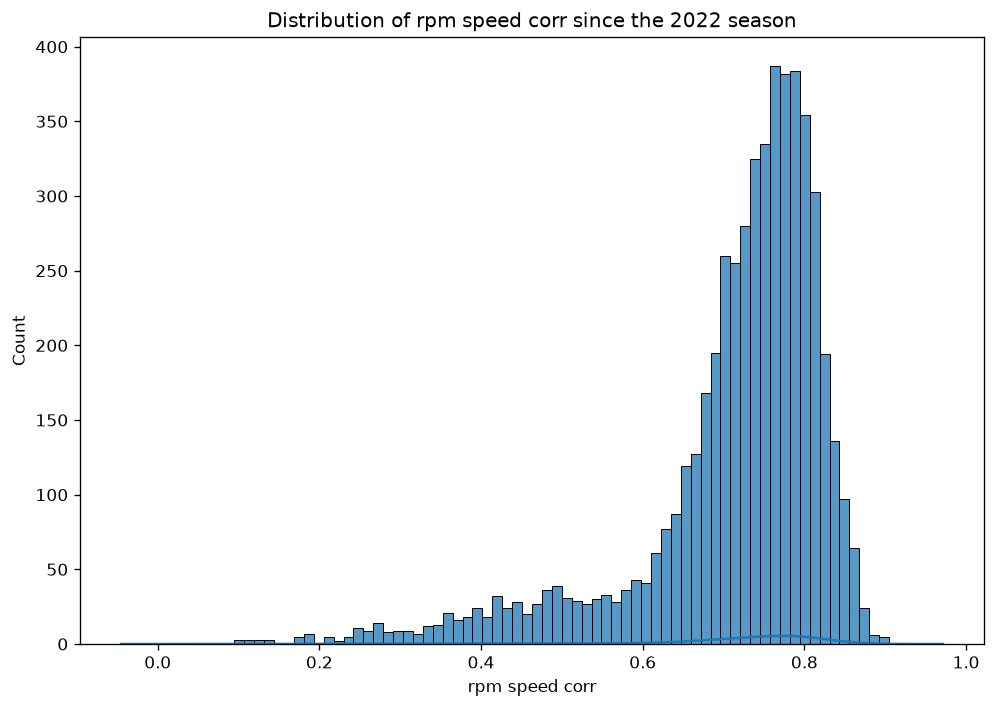

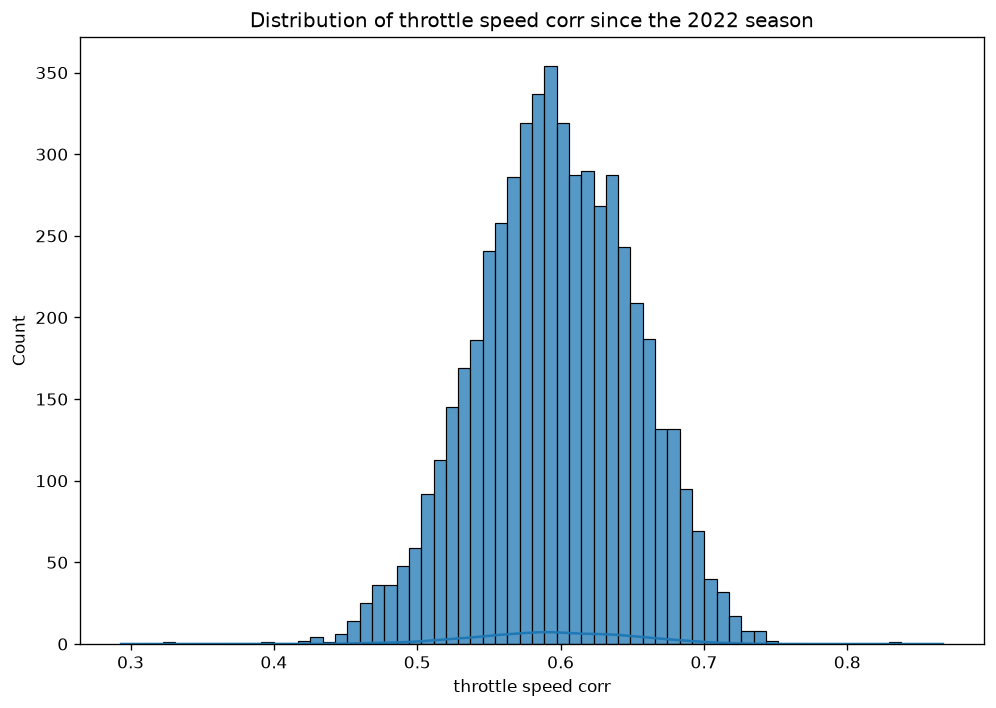

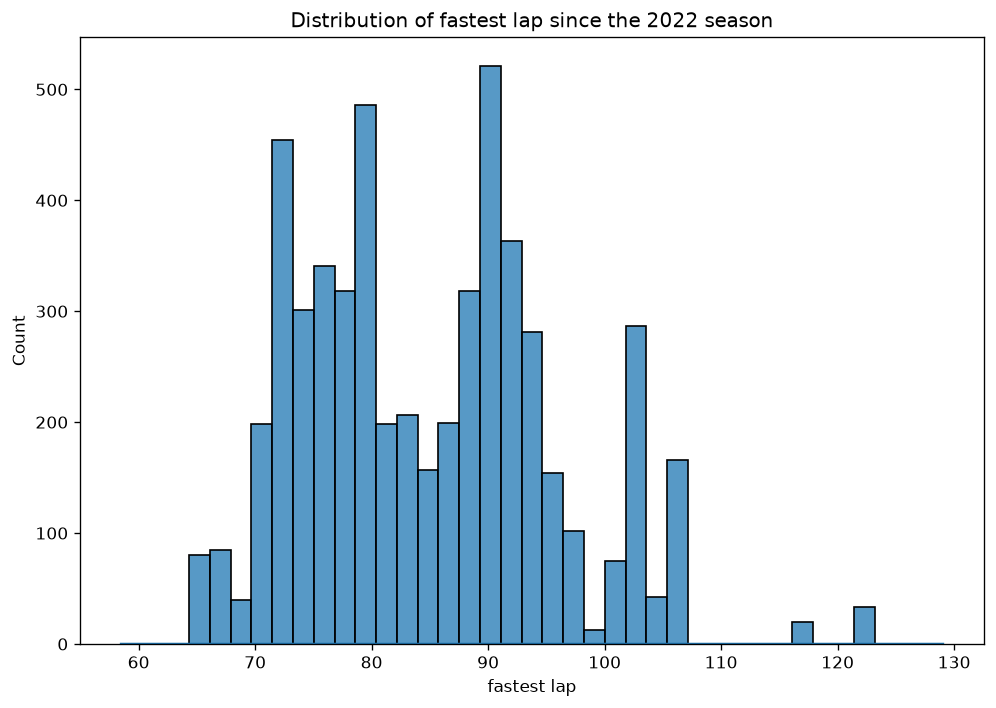

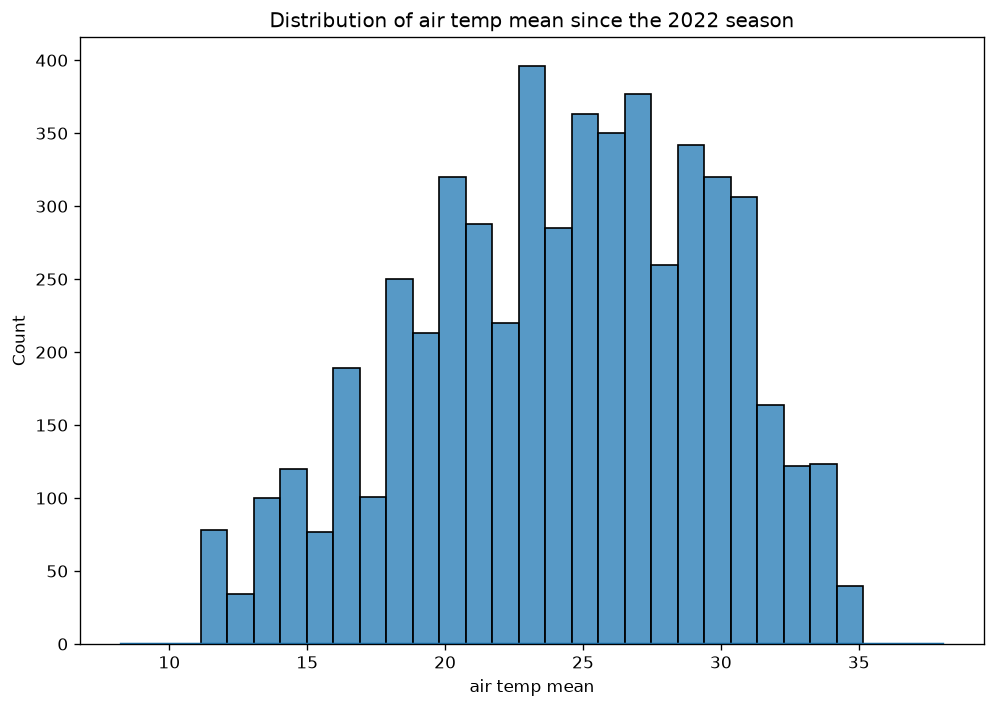

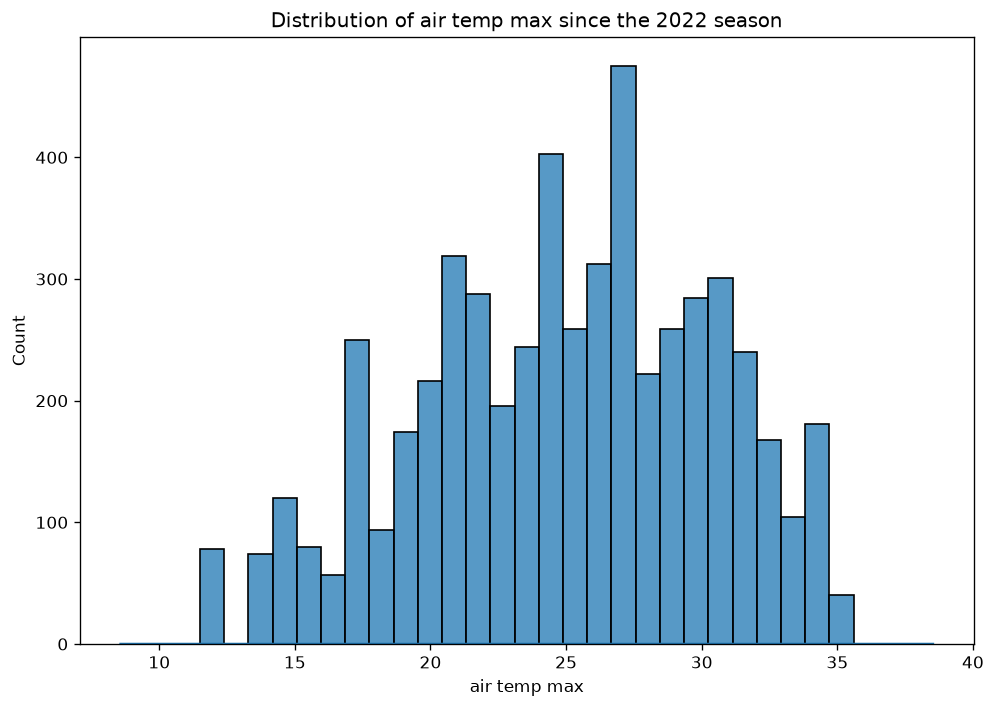

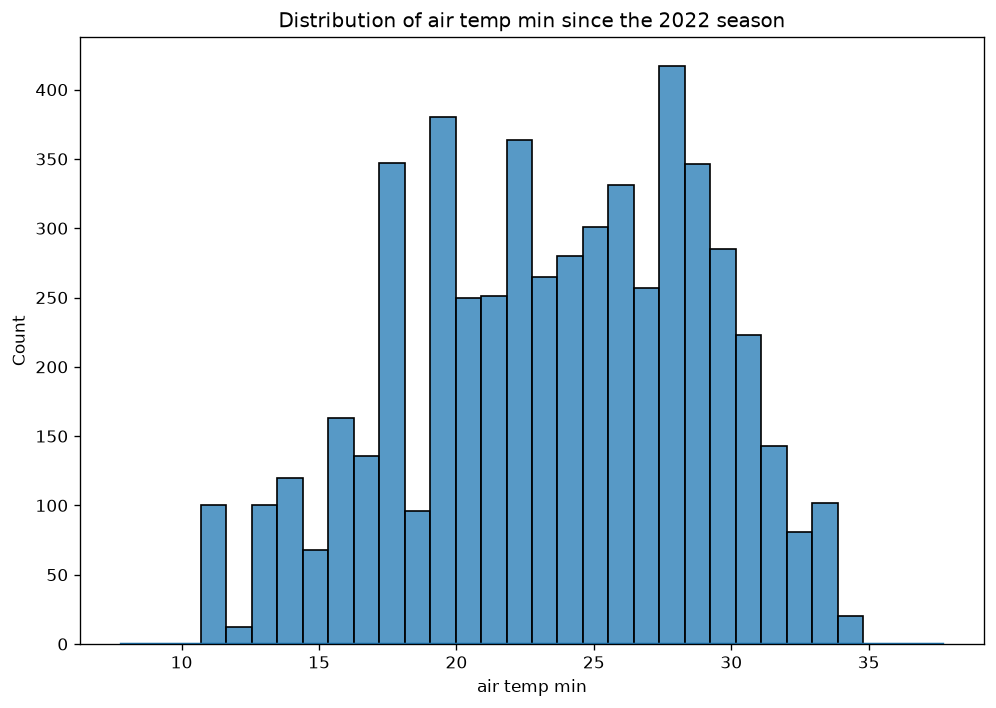

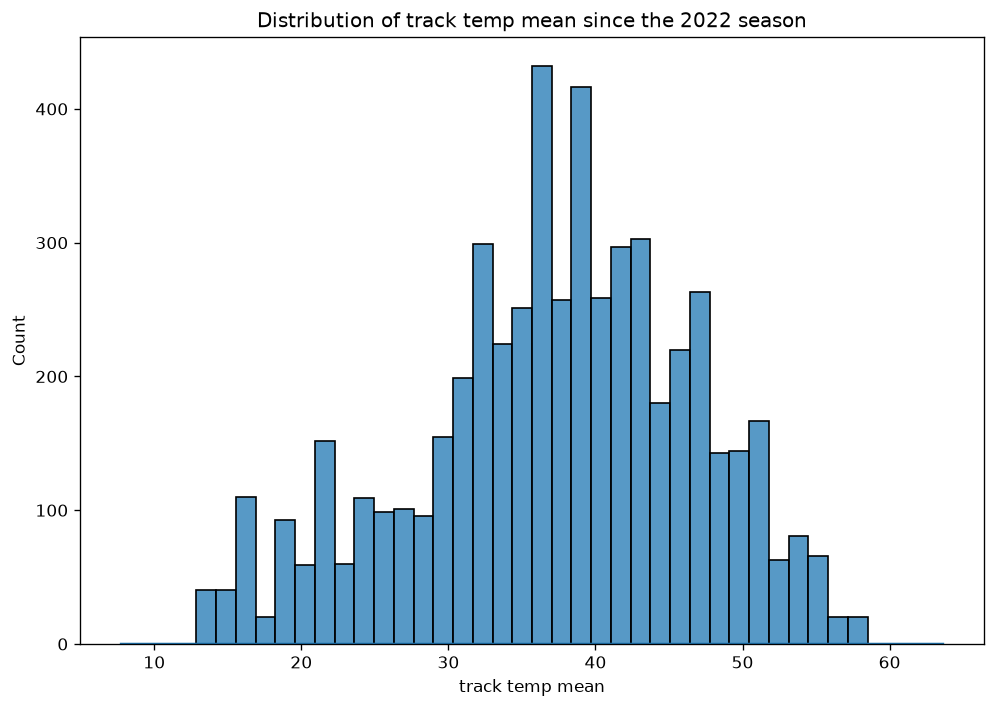

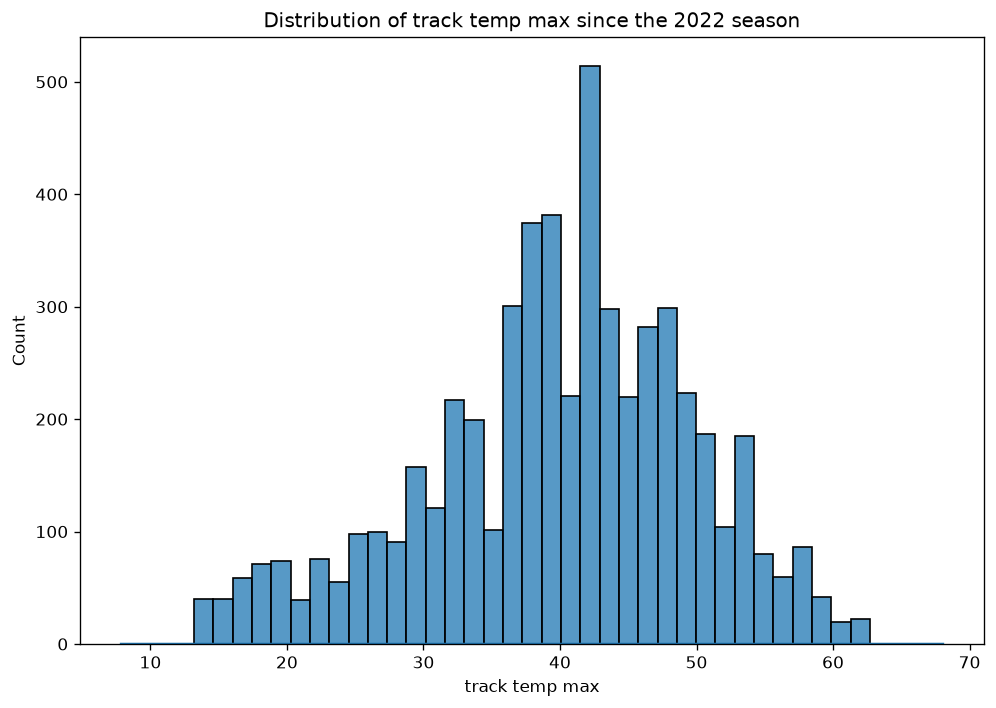

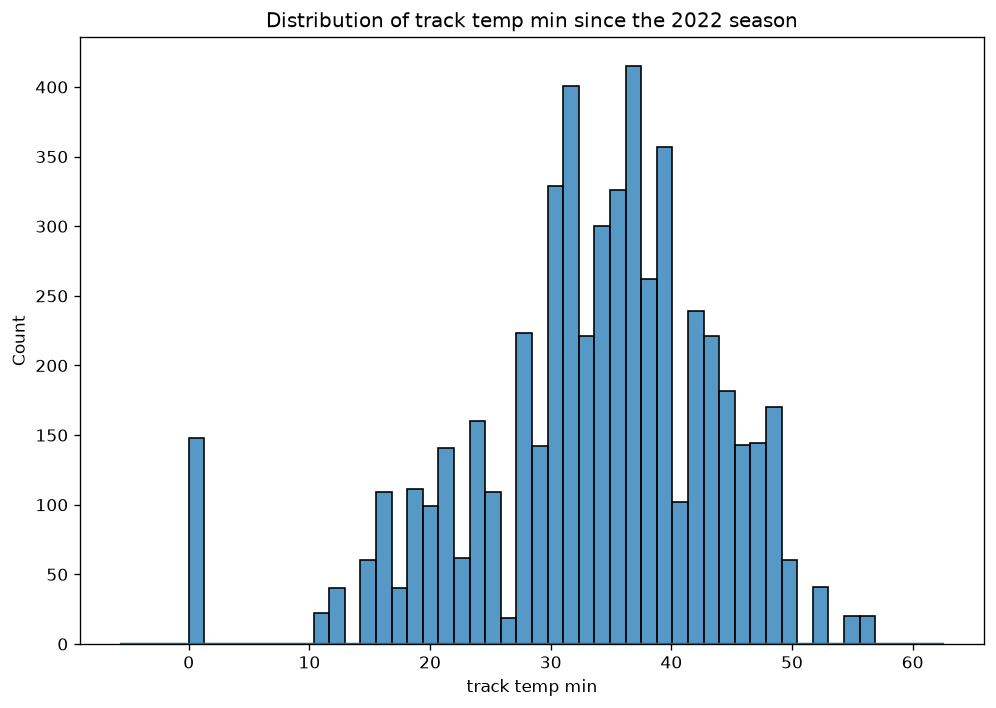

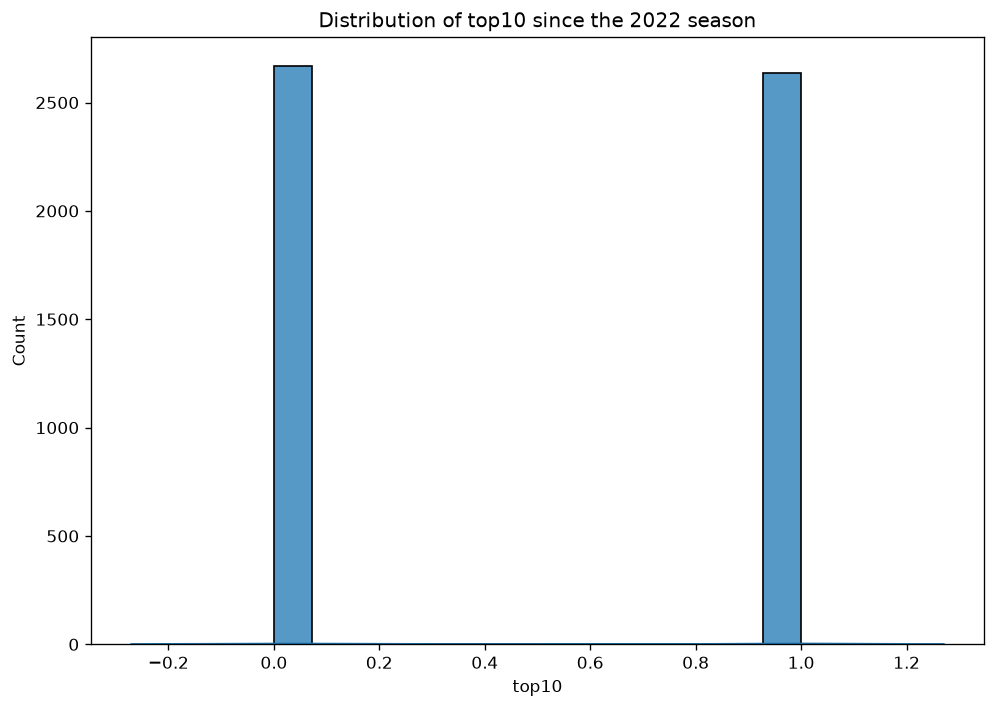

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["figure.dpi"] = 120

for feature in float_columns:
    # Convert to numeric and explicitly retain only finite values
    values = pd.to_numeric(data[feature], errors="coerce")
    x = values.to_numpy(dtype=np.float64, na_value=np.nan)
    x = x[np.isfinite(x)]

    # Skip features without usable data
    if len(x) == 0:
        print(f"Skipping {feature}: no finite values")
        continue

    fig, ax = plt.subplots(figsize=(8.4, 6))

    try:
        # Plot the histogram first; this does not require KDE
        sns.histplot(x=x, ax=ax, kde=False)

        # KDE requires enough observations and variation
        if len(x) >= 3 and np.unique(x).size > 1:
            try:
                sns.kdeplot(x=x, ax=ax)
            except (ValueError, np.linalg.LinAlgError) as exc:
                print(f"KDE failed for {feature}: {exc}")

        ax.set_title(
            f"Distribution of {feature.replace('_', ' ')} "
            "since the 2022 season"
        )
        ax.set_xlabel(feature.replace("_", " "))
        ax.set_ylabel("Count")

        plt.tight_layout()
        plt.show()

    except Exception as exc:
        print(f"Plot failed for {feature}: {type(exc).__name__}: {exc}")

    finally:
        plt.close(fig)

In [43]:
data[["race", "fastest_lap"]].head()

,race,fastest_lap
0,FORMULA 1 GULF AIR BAHRAIN GRAND PRIX 2022,94.193
1,FORMULA 1 GULF AIR BAHRAIN GRAND PRIX 2022,94.193
2,FORMULA 1 GULF AIR BAHRAIN GRAND PRIX 2022,94.193
3,FORMULA 1 GULF AIR BAHRAIN GRAND PRIX 2022,94.193
4,FORMULA 1 GULF AIR BAHRAIN GRAND PRIX 2022,94.193


In [44]:
import fastf1

session = fastf1.get_session(2022, 'Bahrein', 'FP1')
session.load()

# 2. Get the overall fastest lap of the session
fastest_lap = session.laps.pick_fastest()

# 3. Access details about the lap
print(f"Driver: {fastest_lap['Driver']}")
print(f"Lap Time: {fastest_lap['LapTime'].total_seconds()}")
print(f"Team: {fastest_lap['Team']}")


events      WARNING 	Correcting user input 'Bahrein' to 'Bahrain Grand Prix'
core           INFO 	Loading data for Bahrain Grand Prix - Practice 1 [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
req            INFO 	Using cached data for car_data
req            INFO 	Using cached data for position_data
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['1', '3', '4', '6', '10', '11', '14', '16', '18', '20', '22', '23', '24', '27', '31', '44', '47', '55', '63', '77']


Driver: GAS
Lap Time: 94.193
Team: AlphaTauri
